TASK B (Network Metrics)

This notebook explores the three Wikidata editor networks utilizing the metrics of structure provided in the module. The goal is to describe each network and compare them with a baseline of a randomly generated network.

In [22]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from itertools import combinations

Step 1:- Reconstruct the Networks

The process used in constructing the networks for Task A will be maintained so that the metric calculation can be made using the same graph definition.

In [23]:
datasets = {
    "small": "../data/REQUEST_A_QUERY.csv",
    "medium": "../data/USERS.csv",
    "large": "../data/REQUEST_FOR_DELETION.csv"
}

def build_graph(df, user_col="username", context_cols=("page_name", "thread_subject"), max_group_size=100):
    df = df.dropna().copy()
    df[user_col] = df[user_col].astype(str).str.strip()
    for col in context_cols:
        df[col] = df[col].astype(str).str.strip()

    G = nx.Graph()

    for context, group in df.groupby(list(context_cols)):
        users = group[user_col].dropna().unique()

        if len(users) > max_group_size:
            users = users[:max_group_size]

        for u1, u2 in combinations(users, 2):
            G.add_edge(u1, u2)

    return G

graphs = {}
for name, path in datasets.items():
    df = pd.read_csv(path)
    graphs[name] = build_graph(df)

print("Networks reconstructed successfully.")

Networks reconstructed successfully.


Step 2:- Compute basic network metrics

The following metrics are computed for each graph:
- number of nodes
- number of edges
- density
- average degree
- average clustering coefficient
- size of the largest connected component

Path based metrics are later computed later on the largest connected component only

In [24]:
basic_results = []

for name, G in graphs.items():
    n = G.number_of_nodes()
    m = G.number_of_edges()
    density = nx.density(G)
    avg_degree = sum(dict(G.degree()).values()) / n
    avg_clustering = nx.average_clustering(G)

    lcc_nodes = max(nx.connected_components(G), key=len)
    lcc_size = len(lcc_nodes)

    basic_results.append([
        name, n, m, density, avg_degree, avg_clustering, lcc_size
    ])

basic_df = pd.DataFrame(
    basic_results,
    columns=[
        "Dataset", "Nodes", "Edges", "Density",
        "Average Degree", "Average Clustering", "Largest CC Size"
    ]
)

basic_df

,Dataset,Nodes,Edges,Density,Average Degree,Average Clustering,Largest CC Size
0,small,671,1884,0.008381,5.615499,0.533509,665
1,medium,8396,24755,0.000702,5.896856,0.248686,7774
2,large,9887,33497,0.000685,6.775968,0.393854,9870


The table above provides the main descriptive metrics needed for intial comparison across the three networks.

Step 3: Degree Distribution

The degree distribution provides information regarding the number of links that each node is connected to. This helps determine whether the network exhibits random characteristics (homogeneous) or if it is highly concentrated around few nodes (hubs) (heterogeneous).

In [25]:
degree_data = {}

for name, G in graphs.items():
    degrees = [d for n, d in G.degree()]
    degree_data[name] = degrees

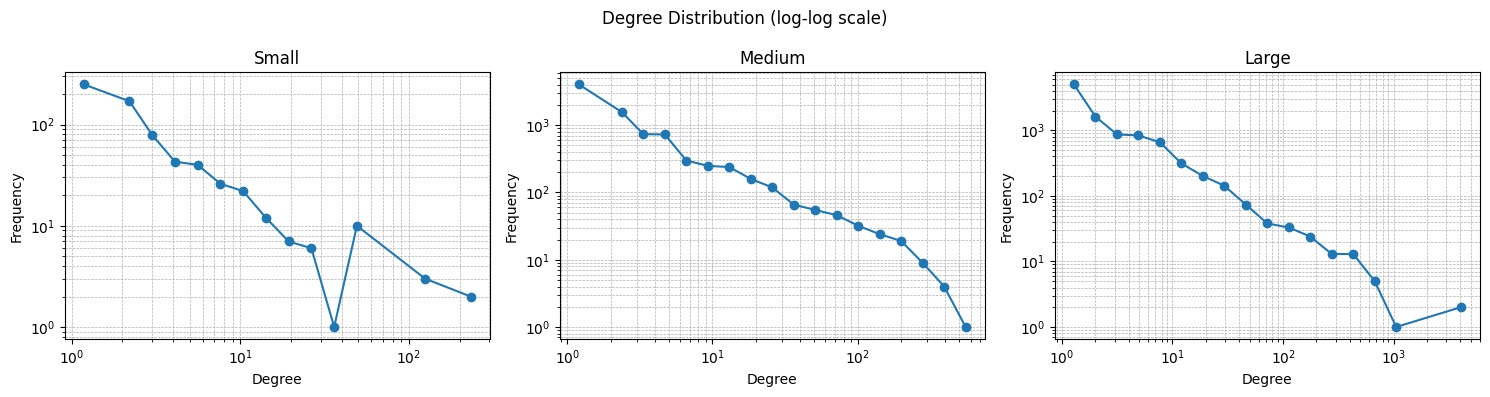

In [27]:
def log_bin(degrees, bins=20):
    degrees = np.array(degrees)
    hist, bin_edges = np.histogram(
        degrees,
        bins=np.logspace(np.log10(1), np.log10(max(degrees)), bins)
    )
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    return bin_centers, hist

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, degrees) in zip(axes, degree_data.items()):
    
    # apply log-binning
    x, y = log_bin(degrees)
    
    # remove zero frequencies
    mask = y > 0
    x, y = x[mask], y[mask]
    
    ax.plot(x, y, marker='o', linestyle='-')
    
    ax.set_xscale("log")
    ax.set_yscale("log")
    
    ax.set_title(name.capitalize())
    ax.set_xlabel("Degree")
    ax.set_ylabel("Frequency")
    
    ax.grid(True, which="both", linestyle="--", linewidth=0.5)

plt.suptitle("Degree Distribution (log-log scale)")
plt.tight_layout()
plt.show()